# Ders 04 · Ters problem — Bi'yi iç sıcaklık ölçümlerinden geri bulmak

**Kolay PINN · Türkişi Engineering** · Lisans + yüksek lisans · Adım 7

Ders 03'te modele bilerek yanlış bir Biot sayısı verdik (Bi = 2, gerçek 4.895); ölçümler hatayı ancak iki kat
düşürebildi. Bugün Bi'yi **ağırlıklarla birlikte öğreniyoruz**:

$$
\min_{\mathbf{w},\,\beta}\ \mathcal{L}_{\mathrm{PDE}}(\mathbf{w}) + \lambda\,\mathcal{L}_{\mathrm{Robin}}(\mathbf{w}, e^{\beta})
+ \mu\,\frac{1}{N_d}\sum_{i=1}^{N_d}\big(\hat\theta(\mathbf{x}_i;\mathbf{w}) - \theta_i^{\mathrm{ö}}\big)^2,
\qquad \mathrm{Bi} = e^{\beta}
$$

Plan:
1. **Klasik referans:** aynı ters problemi seri çözüm + en küçük karelerle çöz; Cramér–Rao sınırıyla
   ulaşılabilecek en iyi doğruluğu hesapla.
2. **Ters PINN:** Bi'yi `torch.nn.Parameter` yap — ve neden saf haliyle **çöktüğünü** gör.
3. **Köşe yanlılığı:** çöküşü öngören basit bir model, ve çözüm.

**Öğrenme hedefleri**
1. Fiziksel bir parametreyi ağırlıklarla birlikte öğrenmek
2. Parametrenin yanlış yere gitmesinin kayıptan mı optimizasyondan mı kaynaklandığını ayırmak
3. Duyarlılık ve Cramér–Rao sınırıyla deney tasarımı yapmak
4. Köşe tabanının getirdiği yanlılığı öngörmek *(yüksek lisans derinliği)*

> Defterdeki eğitimler kısaltılmıştır (her biri ~2 dk, CPU). Tam koşular `runs/inv_*` klasörlerinden yüklenir.

In [1]:
import sys, json, time, math, logging, warnings
from pathlib import Path
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

CASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ROOT = CASE.parents[1]
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(CASE))

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.optimize import minimize_scalar

from kolay_pinn.style import use_slide_style, C, INK, MUTED
from fdm_solver import BI_DEFAULT as Bi_gercek, T_WALL, T_INF
from pinn_forward import MLP, theta_hat, residuals, collocation, evaluate
from pinn_hybrid import sensors

use_slide_style(); plt.rcParams["figure.dpi"] = 110
torch.set_default_dtype(torch.float64)
ASSETS = CASE / "lecture" / "ders04" / "assets"
def goster(ad, genislik=760):
    display(Image(filename=str(ASSETS / ad), width=genislik))

print(f"torch {torch.__version__} · gerçek Bi = {Bi_gercek:.4f} (yalnız ölçüm üretmek ve doğrulamak için)")

torch 2.15.0+cpu · gerçek Bi = 4.8945 (yalnız ölçüm üretmek ve doğrulamak için)


---
## 1 · Klasik referans: ne kadar iyi olabilir?

### 1.1 Ölçümler

Ders 03 ile aynı: FDM ($N = 201$) iç düğümlerinden 20 sensör, $\sigma = 0.01$ (≙ 0.5 °C).

In [2]:
sigma = 0.01
X_d, y_d, temiz = sensors(20, "uniform", sigma, seed=0)
print(f"{len(X_d)} sensör · gürültü RMS = {np.sqrt(np.mean((y_d - temiz)**2)):.4f}")

20 sensör · gürültü RMS = 0.0092


### 1.2 Seri çözüm + en küçük kareler

İleri model analitik seri çözüm (README, Adım 3). Veriyi üreten FDM'den farklı bir model kullanıyoruz; aynı modeli
kullanmak ("ters suç") sonucu yapay olarak iyi gösterir.

$$\mathrm{Bi}^{*} = \arg\min_{\mathrm{Bi}}\ \sum_{i=1}^{N_d}\big(\theta_{\mathrm{seri}}(\mathbf{x}_i;\mathrm{Bi}) - \theta_i^{\mathrm{ö}}\big)^2$$

In [3]:
def theta_seri(X, Bi, n_terim=1500):
    xi, eta = X[:, :1], X[:, 1:2]
    a = np.pi * np.arange(1, 2 * n_terim, 2)[None, :]
    oran = np.exp(-a * eta) * (1 - np.exp(-2 * a * (1 - eta))) / (1 + np.exp(-2 * a))
    return 1.0 - ((4 * Bi / a) / (a + Bi * np.tanh(a)) * np.sin(a * xi) * oran).sum(1)

def klasik_bi(X, y):
    f = lambda b: np.sum((theta_seri(X, np.exp(b)) - y)**2)
    return float(np.exp(minimize_scalar(f, bounds=(np.log(1e-2), np.log(1e3)), method="bounded").x))

t0 = time.perf_counter()
print(f"gürültüsüz veri:  Bi* = {klasik_bi(X_d, temiz):.4f}")
print(f"gürültülü veri:   Bi* = {klasik_bi(X_d, y_d):.4f}   ({1e3 * (time.perf_counter() - t0):.0f} ms)")

gürültüsüz veri:  Bi* = 4.8944
gürültülü veri:   Bi* = 4.6754   (31 ms)


### 1.3 Duyarlılık ve Cramér–Rao sınırı *(yüksek lisans)*

$S(\mathbf{x}) = \partial\theta/\partial\mathrm{Bi}$: Bi biraz değişince bir noktadaki sıcaklık ne kadar değişir?
Gauss gürültüsünde Fisher bilgisi ve ondan gelen alt sınır:

$$I(\mathrm{Bi}) = \frac{1}{\sigma^2}\sum_{i=1}^{N_d} S(\mathbf{x}_i)^2
\quad\Longrightarrow\quad \sigma_{\mathrm{Bi}} \;\geq\; \frac{\sigma}{\sqrt{\sum_i S(\mathbf{x}_i)^2}}$$

Hiçbir yansız yöntem — klasik ya da PINN — bu sınırın altına inemez.

In [4]:
S_ = lambda X, Bi=Bi_gercek, d=1e-4: (theta_seri(X, Bi * (1 + d)) - theta_seri(X, Bi * (1 - d))) / (2 * Bi * d)
sinir = sigma / np.sqrt(np.sum(S_(X_d)**2))
rng = np.random.default_rng(0)
mc = np.array([klasik_bi(X_d, temiz + rng.normal(0, sigma, len(temiz))) for _ in range(200)])
print(f"Cramér–Rao:  σ_Bi ≥ {sinir:.3f}  (%{100 * sinir / Bi_gercek:.1f})")
print(f"Monte Carlo (200 gürültü):  ortalama {mc.mean():.3f}, std {mc.std(ddof=1):.3f}")

Cramér–Rao:  σ_Bi ≥ 0.164  (%3.4)
Monte Carlo (200 gürültü):  ortalama 4.902, std 0.165


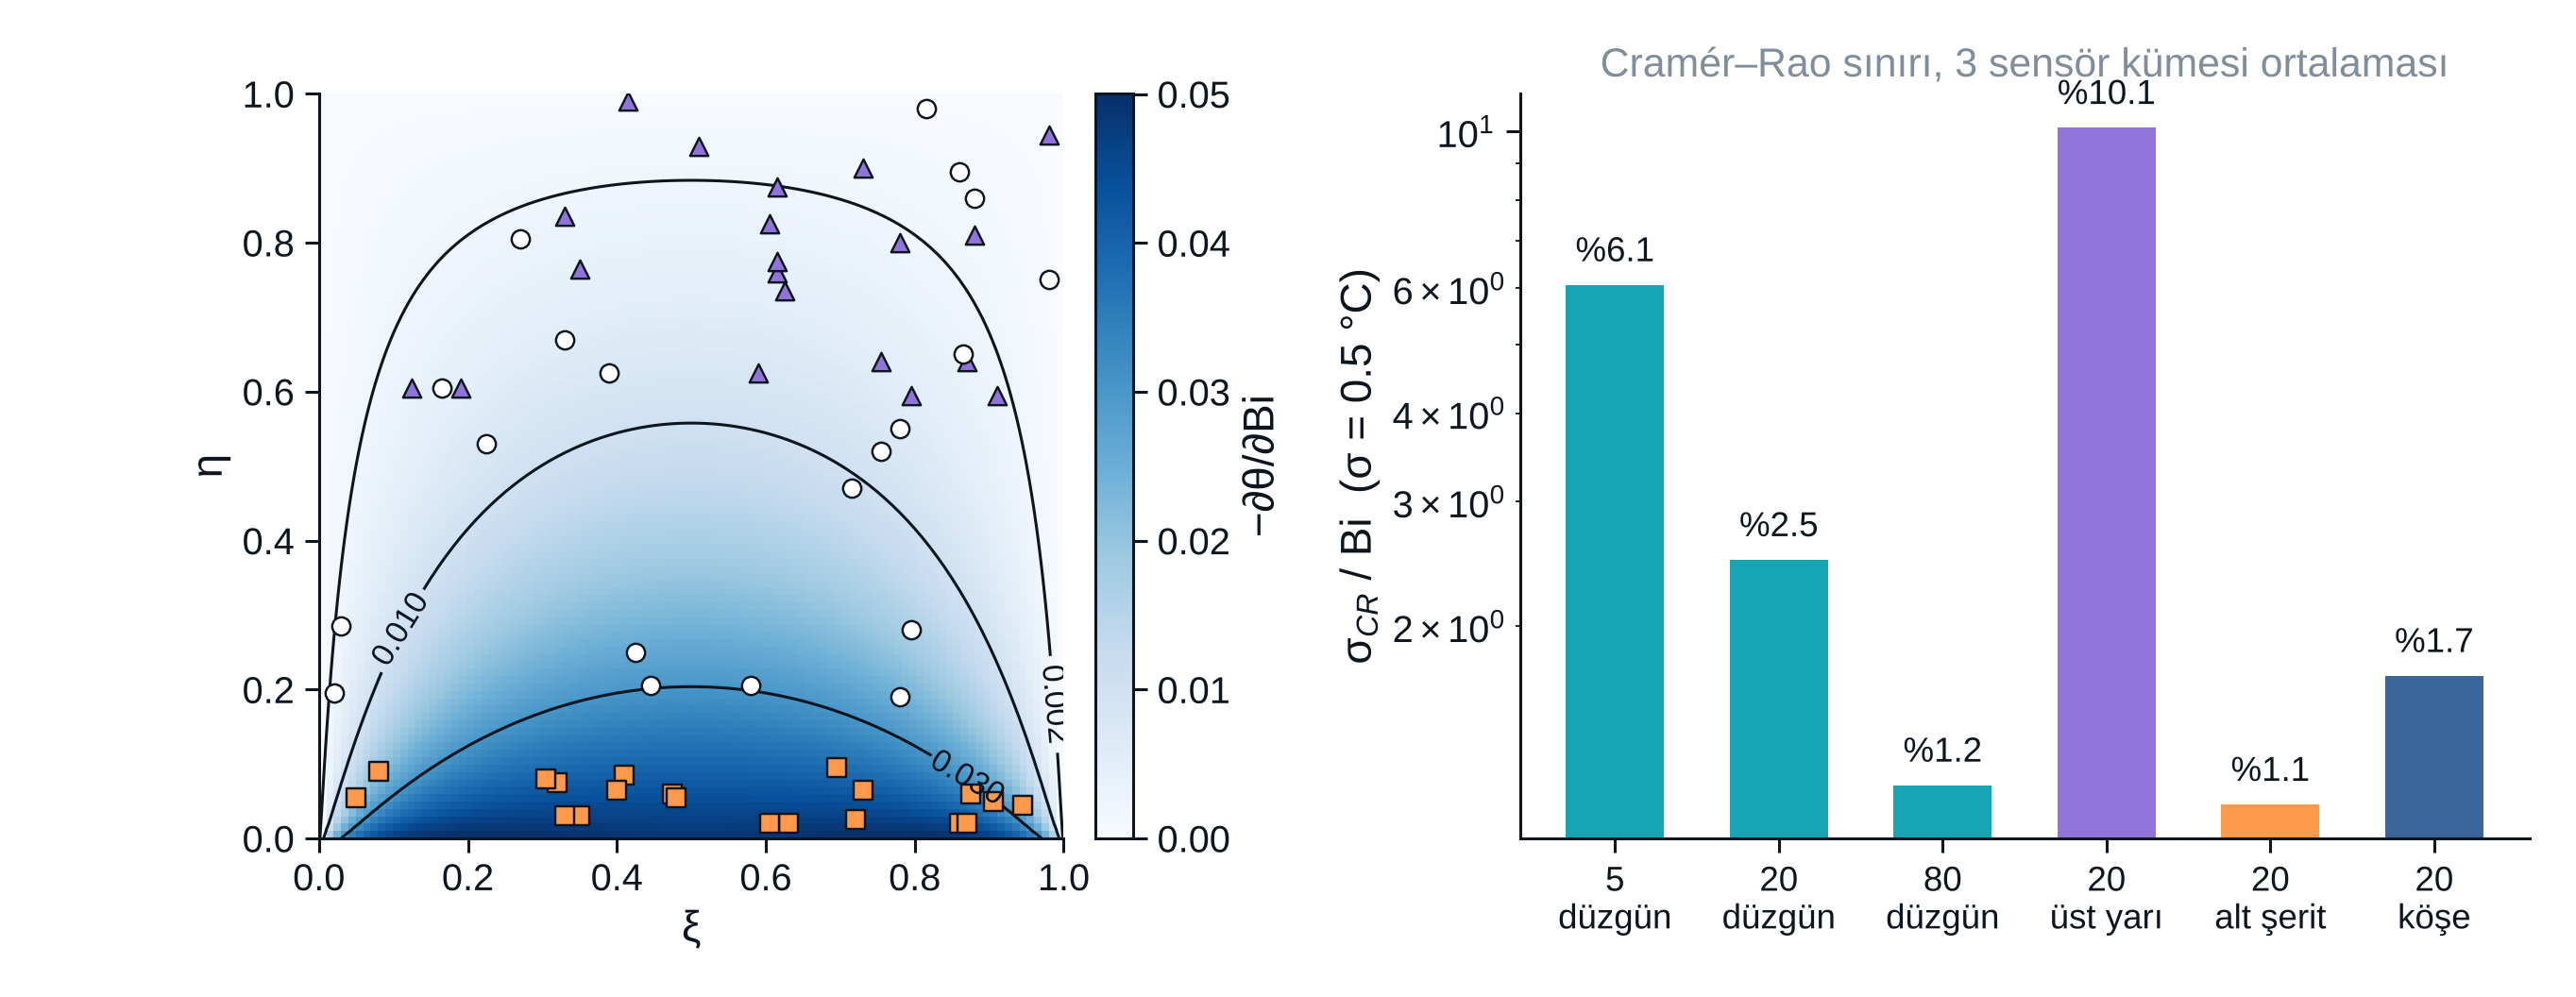

In [5]:
goster("03_sensitivity.png", 900)

**Okuma.** Bilgi soğutulan yüzeyde toplanıyor; üst yarıdaki sensörler neredeyse kör. Alt şeritteki 20 sensör,
düzgün dağılmış 80 sensörle aynı doğruluğu verir. Bu tasarım kararını PINN eğitmeden verdik.

---
## 2 · Ters PINN: Bi'yi öğren

İki satırlık değişiklik: `beta` bir parametre, Robin teriminde `beta.exp()` kullanılıyor. `skip = δ`, köşeden δ
mesafedeki Robin noktalarını kayıptan çıkarır (Ders 02).

In [6]:
def ters_egit(Xd, yd, mu=1.0, skip=0.0, bi0=2.0, seed=0, ADAM=1500, LBFGS=300):
    torch.manual_seed(seed)
    model = MLP(50, 4)
    beta = torch.nn.Parameter(torch.tensor(math.log(bi0)))
    X_int, X_bot = collocation(4096, 256, False, seed, skip)
    Xd_t, yd_t = torch.tensor(Xd), torch.tensor(yd)[:, None]
    def f():
        r_pde, r_rob = residuals(model, X_int, X_bot, beta.exp())
        return (r_pde**2).mean() + (r_rob**2).mean() + mu * ((theta_hat(model, Xd_t) - yd_t)**2).mean()
    opt = torch.optim.Adam([{"params": model.parameters(), "lr": 1e-3}, {"params": [beta], "lr": 1e-2}])
    sch = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1 ** (1 / ADAM))
    yol, t0 = [], time.perf_counter()
    for it in range(ADAM):
        opt.zero_grad(); L = f(); L.backward(); opt.step(); sch.step()
        if it % 25 == 0: yol.append(beta.exp().item())
    lb = torch.optim.LBFGS([*model.parameters(), beta], lr=1.0, max_iter=LBFGS, history_size=50,
                           line_search_fn="strong_wolfe", tolerance_grad=1e-11, tolerance_change=1e-14)
    def closure():
        lb.zero_grad(); L = f(); L.backward(); return L
    lb.step(closure)
    m = evaluate(model, Bi_gercek)[0]
    print(f"δ = {skip}, μ = {mu:g}, Bi₀ = {bi0}:  Bi = {beta.exp().item():.3f} · bağıl L2 = {m['rel_L2']:.2e} · "
          f"{time.perf_counter() - t0:.0f} s")
    return beta.exp().item(), np.array(yol), m

### 2.1 Saf ayar: δ = 0, μ = 1

In [7]:
bi_saf, yol_saf, _ = ters_egit(X_d, y_d, mu=1.0, skip=0.0)

δ = 0.0, μ = 1, Bi₀ = 2.0:  Bi = 0.098 · bağıl L2 = 2.36e-01 · 81 s


Bi gerçek değere değil, **sıfıra** gidiyor. Neden? Başlangıçta $\hat\theta \approx 1$, Robin artığı
$\approx -\mathrm{Bi}$, Robin kaybı $\approx \mathrm{Bi}^2$. Bi → 0'da $\theta \equiv 1$ fiziği tam sağlar; bedeli
yalnız veri terimidir. Doğru Bi'de ise köşe çelişkisi Robin kaybına bir taban ekler. İkisini karşılaştıralım:

In [8]:
S7 = json.loads((CASE / "data" / "summary_inverse.json").read_text())
c = S7["c_corner"]
print(f"doğru Bi'de köşe tabanı ≈ c·Bi² = {c:.2e} × {Bi_gercek:.2f}² = {c * Bi_gercek**2:.3f}")
print(f"Bi → 0'da veri terimi ≈ mean((1 − θ_ö)²) = {np.mean((1 - y_d)**2):.3f}")
print("μ = 1'de yanlış çözüm daha düşük kayıp verir: optimizer değil, kayıp yanlış.")

doğru Bi'de köşe tabanı ≈ c·Bi² = 3.31e-03 × 4.89² = 0.079
Bi → 0'da veri terimi ≈ mean((1 − θ_ö)²) = 0.028
μ = 1'de yanlış çözüm daha düşük kayıp verir: optimizer değil, kayıp yanlış.


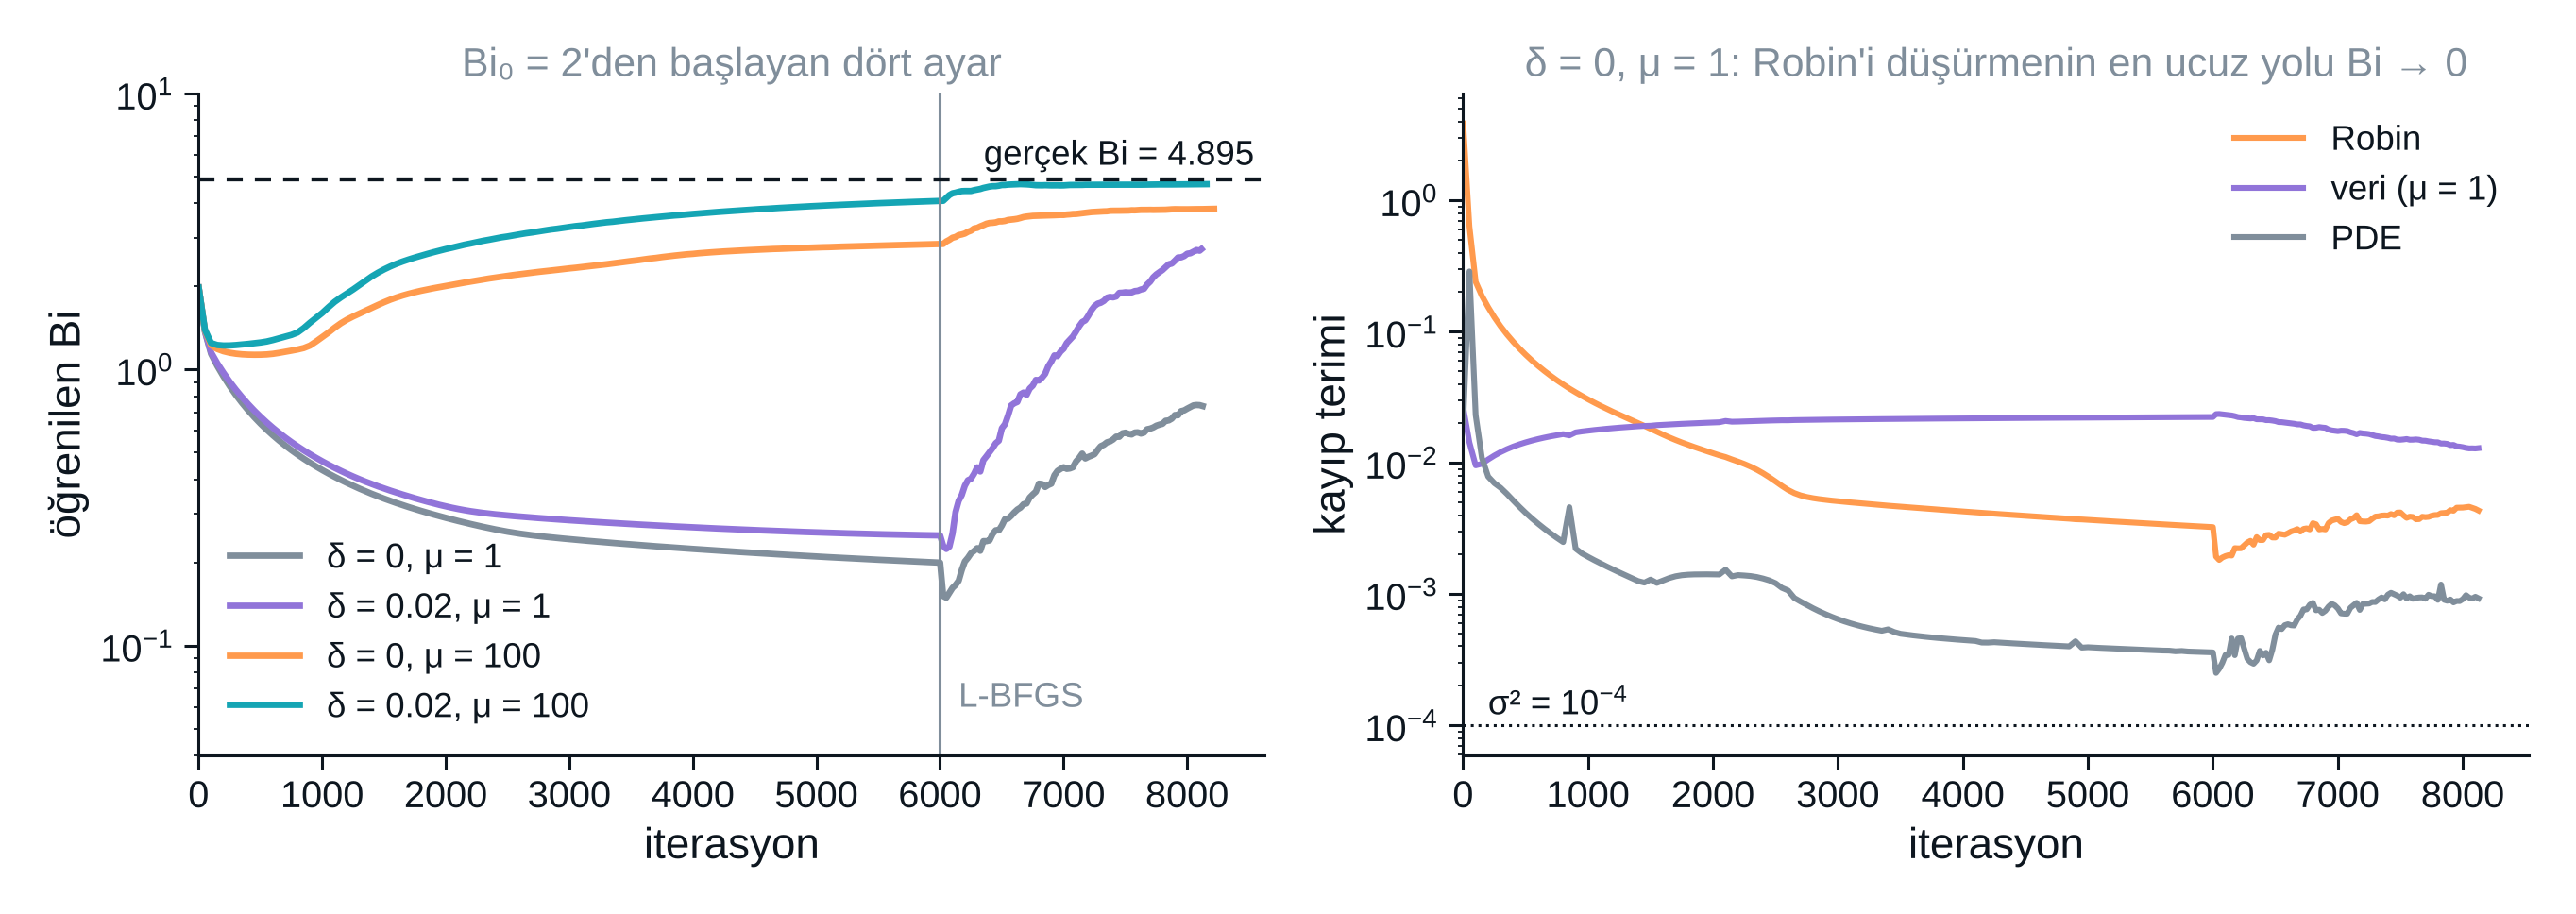

In [9]:
goster("01_trap.png", 900)

### 2.2 Önerilen ayar: δ = 0.02, μ = 100

Köşe şeridini Robin kaybından çıkarıp veri terimini fizik tabanıyla aynı mertebeye getiriyoruz
($\mu\sigma^2 \approx 10^{-2}$).

δ = 0.02, μ = 100, Bi₀ = 2.0:  Bi = 3.942 · bağıl L2 = 1.81e-02 · 78 s


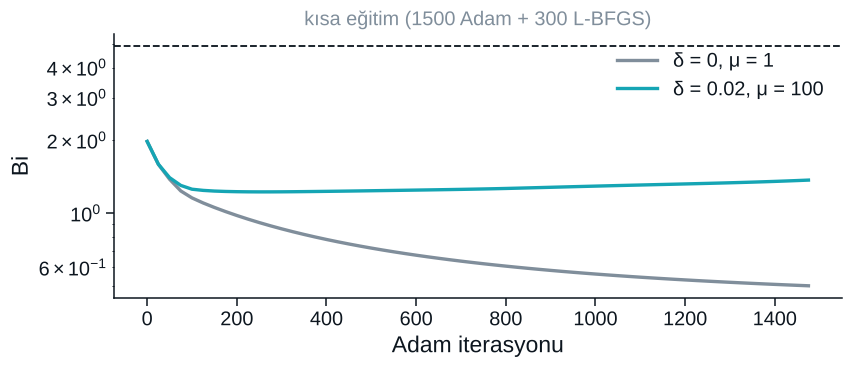

klasik, aynı veri: Bi* = 4.675 ± 0.164


In [10]:
bi_on, yol_on, m_on = ters_egit(X_d, y_d, mu=100.0, skip=0.02)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(len(yol_saf)) * 25, yol_saf, color=C["titanyum"], label="δ = 0, μ = 1")
ax.plot(np.arange(len(yol_on)) * 25, yol_on, color=C["plan"], label="δ = 0.02, μ = 100")
ax.axhline(Bi_gercek, color=INK, ls="--", lw=1.2)
ax.set_yscale("log"); ax.set_xlabel("Adam iterasyonu"); ax.set_ylabel("Bi"); ax.legend()
ax.set_title("kısa eğitim (1500 Adam + 300 L-BFGS)", fontsize=13, color=MUTED)
plt.tight_layout(); plt.show()
print(f"klasik, aynı veri: Bi* = {klasik_bi(X_d, y_d):.3f} ± {sinir:.3f}")

**Okuma.** Kısa eğitimde Bi doğru yöne gidiyor ama henüz yakınsamadı: köşe dışlanınca Bi yavaş yükselir ve son adımı
L-BFGS atar. Tam koşu (6000 Adam + 2000 L-BFGS) aynı veriyle aşağıdaki değere ulaşıyor:

In [11]:
m_tam = json.loads((CASE / "runs" / "inv_n20_s0" / "metrics.json").read_text())
print(f"tam koşu: Bi = {m_tam['Bi_est']:.3f} · bağıl L2 = {m_tam['rel_L2']:.2e} · klasik {klasik_bi(X_d, y_d):.3f} ± {sinir:.3f}")

tam koşu: Bi = 4.693 · bağıl L2 = 4.89e-03 · klasik 4.675 ± 0.164


---
## 3 · Köşe yanlılığı *(yüksek lisans)*

Köşe tabanı $\approx c\,\mathrm{Bi}^2$, veri terimi en iyi tahmin $\mathrm{Bi}^{*}$ çevresinde
$\approx \mu\,m\,(\mathrm{Bi} - \mathrm{Bi}^{*})^2$, $m = \frac{1}{N_d}\sum_i S_i^2$. Toplamın minimumu:

$$\mathrm{Bi}_{\mathrm{PINN}} \approx \frac{\mu\,m}{c + \mu\,m}\,\mathrm{Bi}^{*}$$

$c$'yi Ders 02'nin veri yok koşularından okuyoruz — ters koşulara bakmadan bir öngörü.

In [12]:
m = np.mean(S_(X_d)**2); b_star = klasik_bi(X_d, y_d)
print(f"c = {c:.2e} · m = {m:.2e} · Bi* = {b_star:.3f}\n")
print(f"{'μ':>6s} {'öngörü':>8s} {'PINN (tam koşu)':>16s}")
for mu, v in S7["mu_scan"].items():
    print(f"{mu:>6s} {float(mu) * m * b_star / (c + float(mu) * m):8.3f} {v['Bi_est']:16.3f}")

c = 3.31e-03 · m = 1.85e-04 · Bi* = 4.675

     μ   öngörü  PINN (tam koşu)
     1    0.248            0.737
    10    1.677            2.494
   100    3.966            3.820
  1000    4.593            4.319


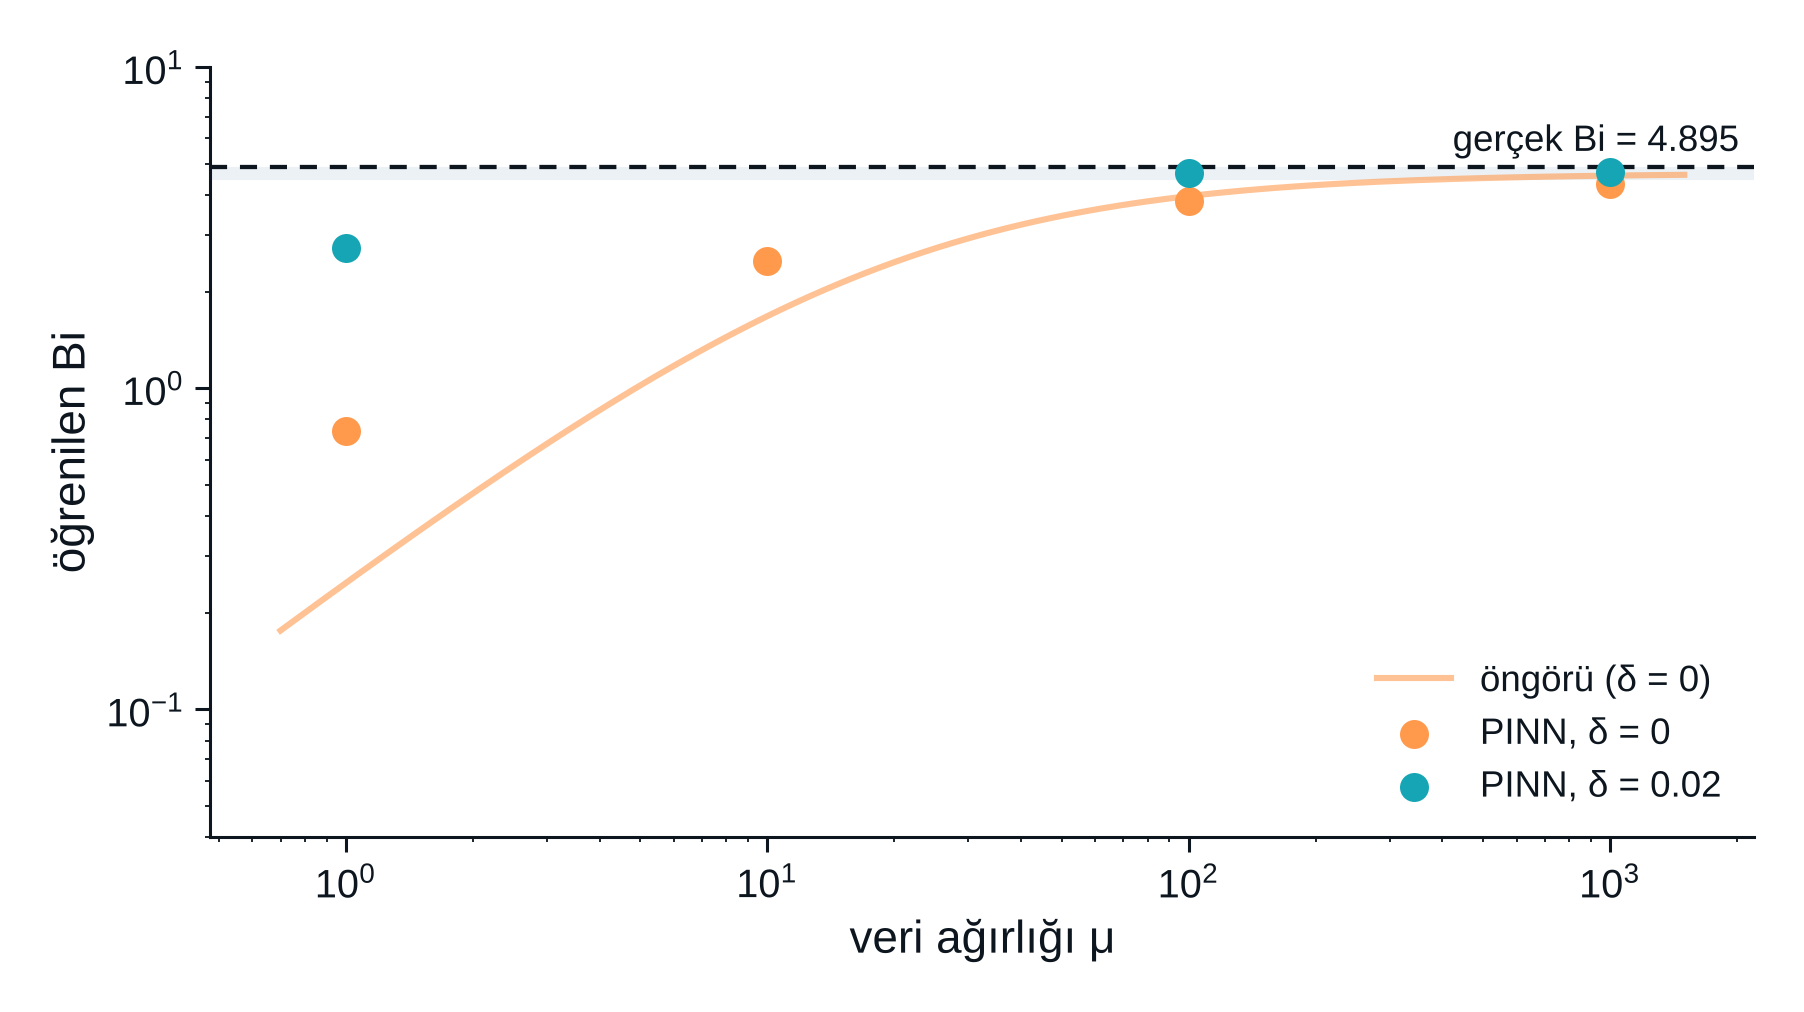

In [13]:
goster("02_corner_bias.png", 700)

### 3.1 Tam koşular: PINN ve klasik, aynı veriyle

Önerilen ayar (δ = 0.02, μ = 100), üç tohum. Asıl ölçüt gerçek Bi değil, **aynı verinin** klasik tahmini:
fark Cramér–Rao sınırının mertebesindeyse kalan hata gürültüden gelir.

In [14]:
print(f"{'grup':14s} {'PINN Bi (3 tohum)':>24s} {'klasik Bi*':>24s} {'σ_CR':>6s} {'fark/σ_CR':>9s}")
for g, v in S7["groups"].items():
    p = " ".join(f"{r['Bi_est']:.3f}" for r in v["runs"]); k = " ".join(f"{r['Bi_classical']:.3f}" for r in v["runs"])
    print(f"{g:14s} {p:>24s} {k:>24s} {v['mean_crlb']:6.3f} {v['gap_over_crlb']:9.2f}")
print("\nek:", {g: round(v["Bi_est"], 3) for g, v in S7["extra"].items()})

grup                  PINN Bi (3 tohum)               klasik Bi*   σ_CR fark/σ_CR
5 düzgün              5.151 4.931 4.275        5.109 4.883 4.362  0.297      0.20
20 düzgün             4.693 4.971 4.968        4.675 4.934 4.993  0.122      0.22
80 düzgün             4.980 4.886 4.873        4.975 4.871 4.938  0.058      0.49
20 üst yarı           3.555 5.244 4.972        3.720 5.287 5.312  0.495      0.37
20 alt şerit          4.841 4.889 4.993        4.795 4.880 4.968  0.055      0.49

ek: {'σ = 0': 4.897, 'σ = 0.05': 3.957, 'Bi₀ = 0.5': 4.682, 'Bi₀ = 8': 4.681, 'ısınma, μ = 1': 2.167}


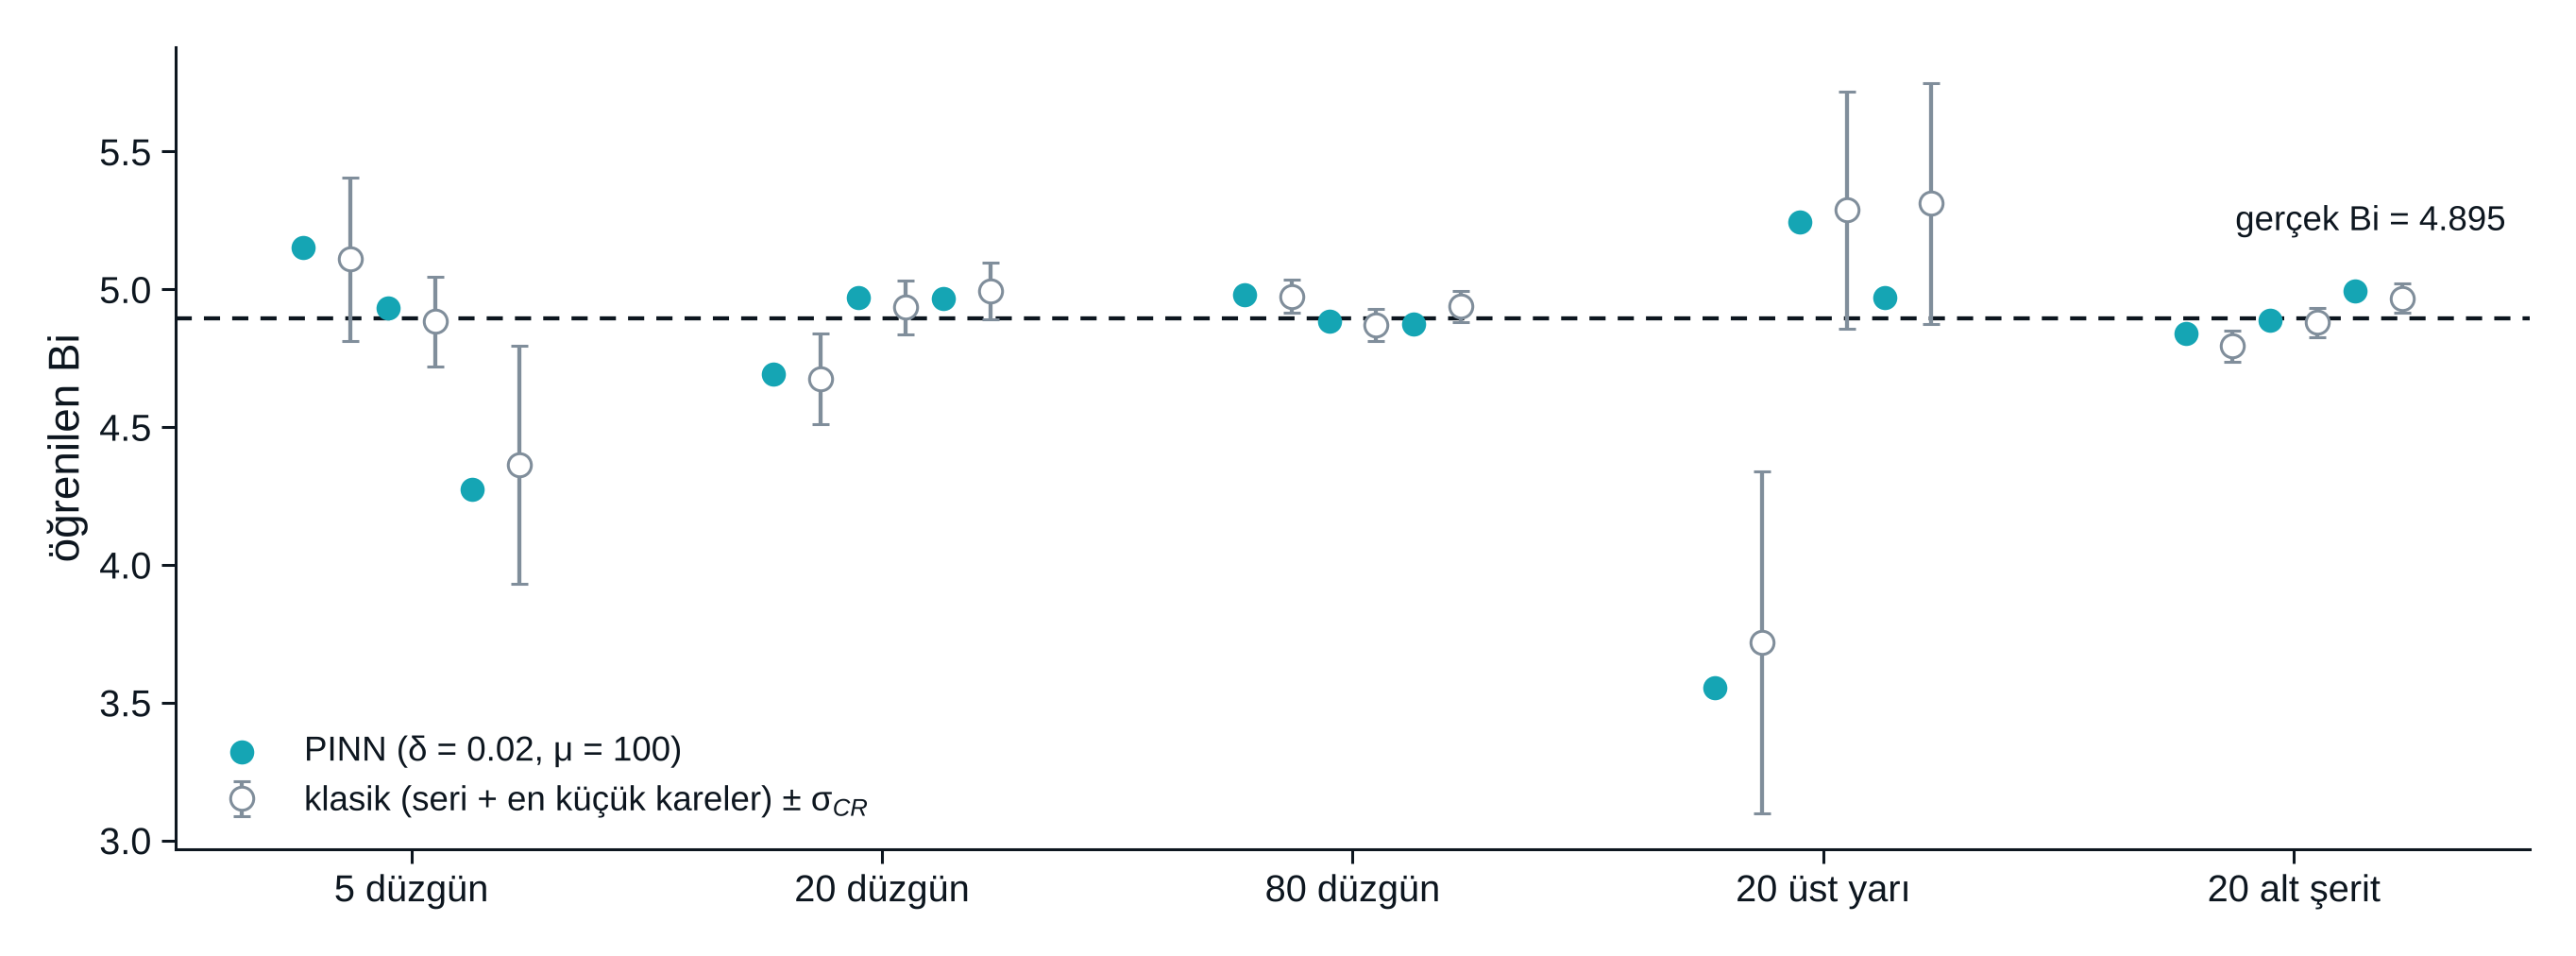

In [15]:
goster("04_pinn_vs_classical.png", 900)

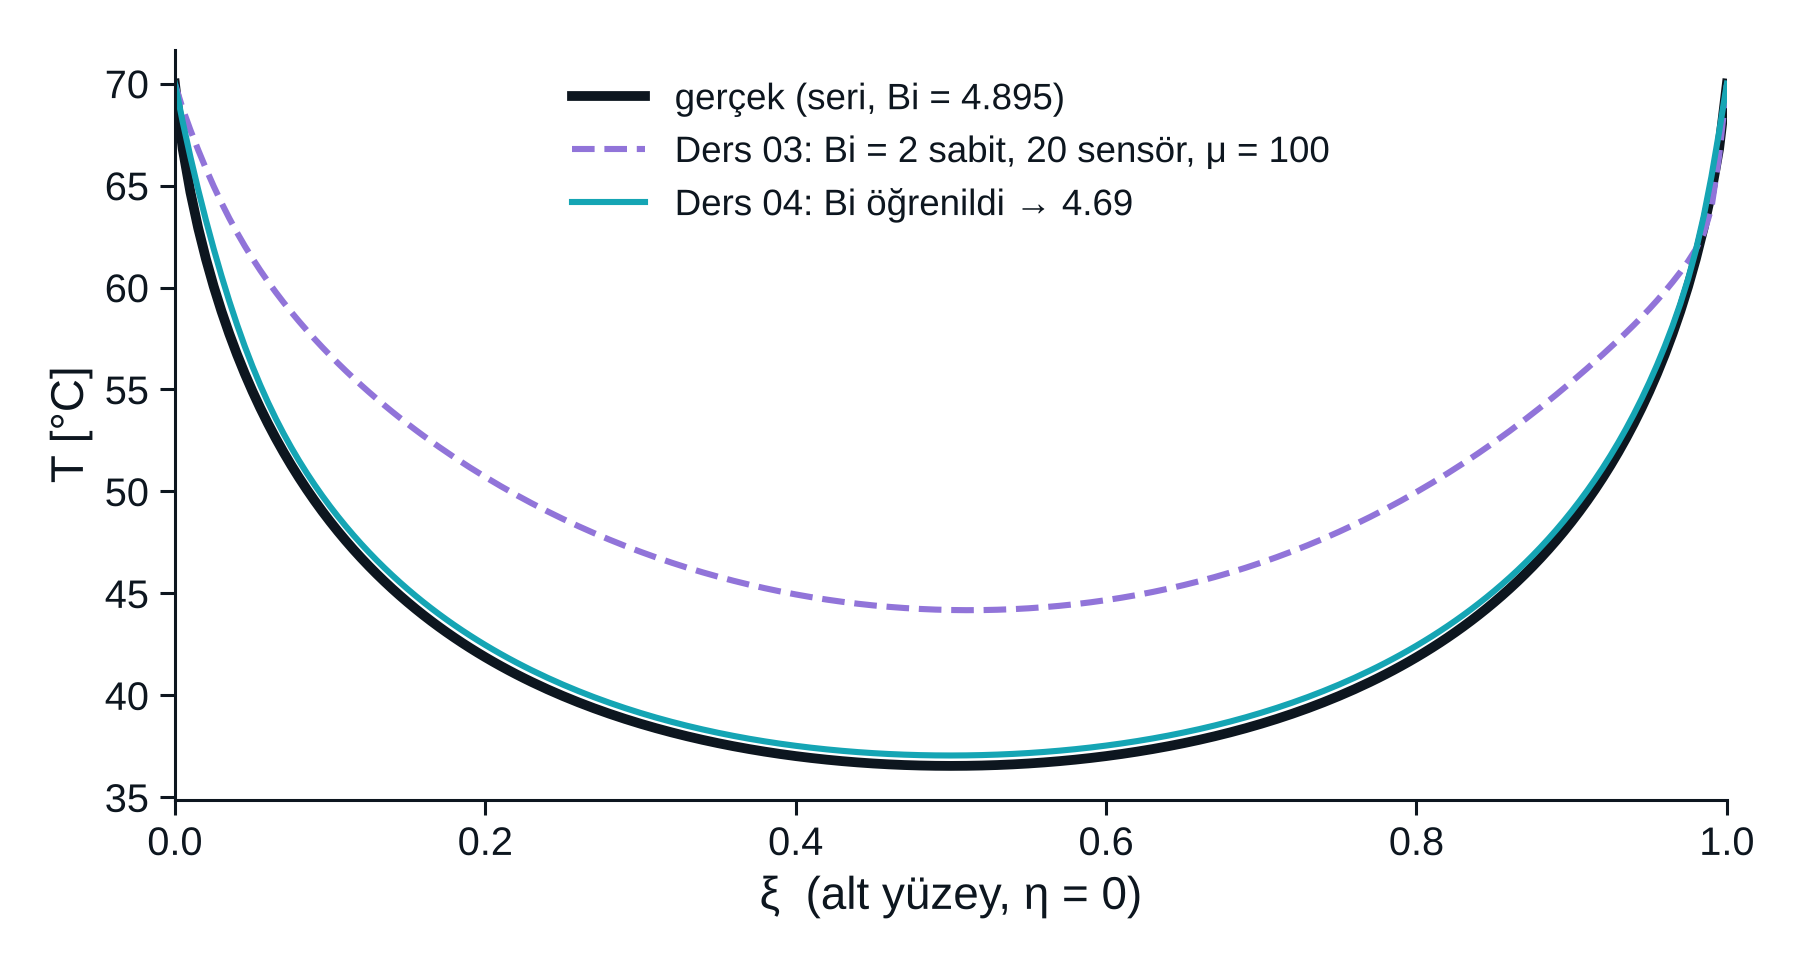

In [16]:
goster("05_bottom_fixed.png", 700)

## Özet

- Bi'yi öğrenilecek parametre yapmak iki satır; ama **saf kayıpla Bi sıfıra çöker**. Sebep kaybın kendisi:
  köşe çelişkisinin tabanı $c\,\mathrm{Bi}^2$ ile büyür ve yanlış çözümü ödüllendirir.
- Ulaşılabilecek en iyi doğruluğu **klasik model ve Cramér–Rao sınırıyla önceden** hesaplayın; sensör yeri sayısından önemli.
- Köşeyi dışlayıp ($\delta = 0.02$) veri terimini fizik tabanıyla aynı mertebeye getirince ($\mu = 100$) PINN,
  aynı verinin klasik tahmininden gürültü sınırı kadar uzakta kalır ve başlangıca duyarsızdır.

## Alıştırmalar

**Lisans:** (1) 20 sensörü alt şeride koyun (`sensors(20, "bottom", ...)`) ve Bi hatasını karşılaştırın ·
(2) $\sigma = 0.05$ ile Bi'yi bulun; Cramér–Rao sınırı ne öngörüyor? · (3) Öğrenilen Bi'den $h$ ve $Q'$'yu hesaplayın.

**Yüksek lisans:** (1) Yanlılık formülünü $\delta = 0$'da $\mu = 30$ ve $300$ için sınayın ·
(2) $\mu$'yü gradyan dengelemeyle uyarlayın (Wang vd. 2021) · (3) Konuma bağlı $h(\xi)$'yi küçük bir ikinci ağla öğrenin.

In [17]:
# Alıştırma alanı — Lisans 1: alt şerit
X_b, y_b, _ = sensors(20, "bottom", sigma, seed=0)
print(f"alt şerit: klasik Bi* = {klasik_bi(X_b, y_b):.3f} ± {sigma / np.sqrt(np.sum(S_(X_b)**2)):.3f}")
# ters_egit(X_b, y_b, mu=100.0, skip=0.02)   # açıp çalıştırın (~2 dk)

alt şerit: klasik Bi* = 4.795 ± 0.057
